# Assignment 3: Build and Evaluate a CNN

**Goal:** load and visualise Fashion-MNIST images, build a small convolutional neural network (CNN), compare it with a
fully connected baseline, plot the training and validation curves, and explain five misclassified examples.

| Assignment item | Where it is in this notebook |
|---|---|
| 1. Load and visualise Fashion-MNIST images | Steps 2 to 4 |
| 2. Build a small CNN | Steps 5 and 6 |
| 3. Compare it with a fully connected baseline | Steps 6, 7 and 9 |
| 4. Plot training and validation curves | Step 8 |
| 5. Explain five misclassified examples | Step 10 |

**Key ideas used here (the Week 3 topics)**
- **Images as tensors:** a grayscale image is a grid of numbers. PyTorch stores a batch of images as
  `(batch, channels, height, width)`, for example `(128, 1, 28, 28)`.
- **Convolution:** a small filter (here 3 x 3) slides over the image and measures how strongly each patch matches a pattern such as an edge.
  A CNN **learns** its own filters.
- **Padding and pooling:** padding keeps the image size after a convolution. Max-pooling halves the size and keeps the strongest response.
- **CNN vs fully connected:** a fully connected network flattens the image and forgets which pixels are neighbours.
  A CNN keeps the 2D structure and reuses the same filter everywhere, so it needs fewer parameters.
- **Normalisation:** pixels are rescaled with the training-set mean and standard deviation, which makes training smoother.
- **Datasets and data loaders:** a dataset returns one `(image, label)` pair. A data loader groups them into shuffled batches.

## Step 1: Imports and setup

In [1]:
import copy
import json
import os
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# Fixed seeds so your results are repeatable
torch.manual_seed(42)
np.random.seed(42)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


## Step 2: Load Fashion-MNIST and look at one image as a tensor

Fashion-MNIST has 70,000 grayscale pictures of clothing, each 28 x 28 pixels, in 10 categories
(60,000 for training and 10,000 for testing). The first run downloads about 30 MB into a folder called `fashion_mnist_data`
in your user folder.

`ToTensor()` turns an image into a tensor of shape `(1, 28, 28)` with pixel values between 0 (black) and 1 (white).

In [2]:
DATA_DIR = os.path.join(os.path.expanduser("~"), "fashion_mnist_data")
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

raw_train = datasets.FashionMNIST(DATA_DIR, train=True, download=True, transform=transforms.ToTensor())
test_raw = datasets.FashionMNIST(DATA_DIR, train=False, download=True).data.numpy()   # original test pixels, for pictures later

image, label = raw_train[0]
print("One image as a tensor:", tuple(image.shape), "(channels, height, width) | data type:", image.dtype)
print("Smallest / largest pixel value:", float(image.min()), "/", float(image.max()))
print("Its label:", label, "=", CLASS_NAMES[label])
print("\nA 6 x 6 patch from the middle of the image (0 = black, 1 = white):")
print(np.round(image[0, 11:17, 11:17].numpy(), 2))

One image as a tensor: (1, 28, 28) (channels, height, width) | data type: torch.float32
Smallest / largest pixel value: 0.0 / 1.0
Its label: 9 = Ankle boot

A 6 x 6 patch from the middle of the image (0 = black, 1 = white):
[[0.   0.05 0.86 0.86 0.83 0.85]
 [0.   0.39 0.96 0.87 0.86 0.85]
 [0.   0.22 0.93 0.89 0.9  0.89]
 [0.   0.93 0.89 0.85 0.87 0.87]
 [0.8  0.89 0.81 0.84 0.87 0.85]
 [0.87 0.85 0.89 0.78 0.8  0.83]]


## Step 3: Visualise the data

First 16 training images, then a bar chart of how many training images each category has (a balanced dataset is easier to learn from).

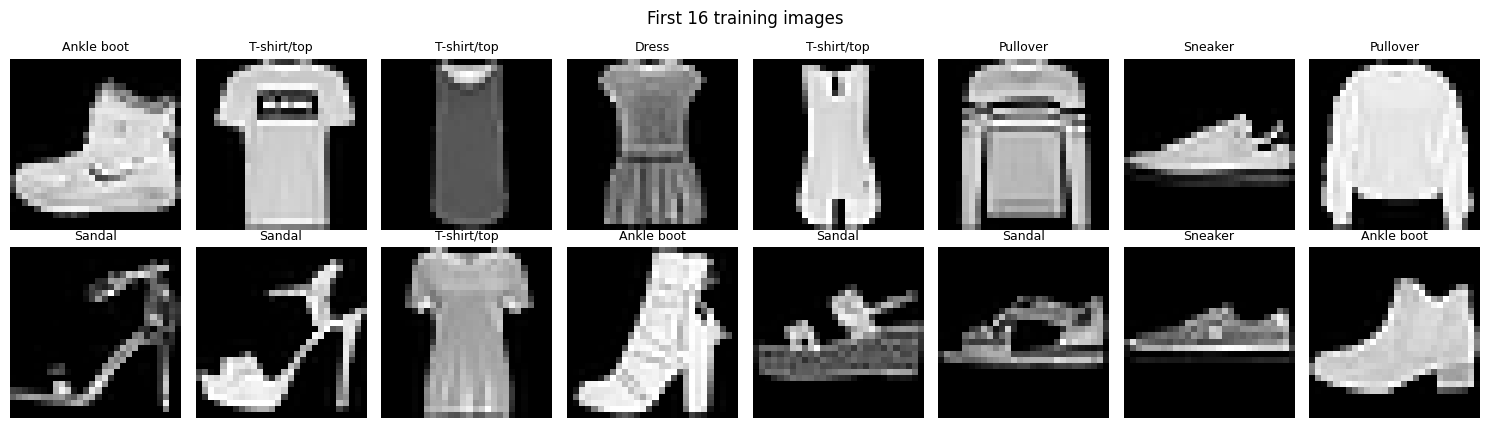

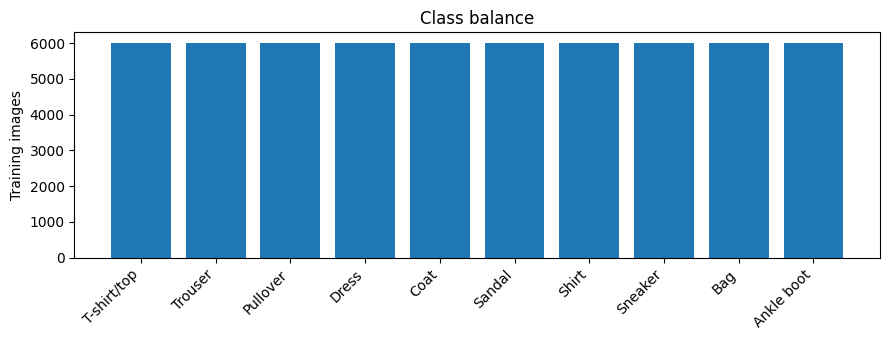

Images per class: {'T-shirt/top': 6000, 'Trouser': 6000, 'Pullover': 6000, 'Dress': 6000, 'Coat': 6000, 'Sandal': 6000, 'Shirt': 6000, 'Sneaker': 6000, 'Bag': 6000, 'Ankle boot': 6000}


In [3]:
fig, axes = plt.subplots(2, 8, figsize=(15, 4.4))
for ax, i in zip(axes.ravel(), range(16)):
    ax.imshow(raw_train.data[i].numpy(), cmap="gray")
    ax.set_title(CLASS_NAMES[int(raw_train.targets[i])], fontsize=9)
    ax.axis("off")
plt.suptitle("First 16 training images")
plt.tight_layout()
plt.savefig("sample_images.png", dpi=150)
plt.show()

counts = np.bincount(raw_train.targets.numpy(), minlength=10)
plt.figure(figsize=(9, 3.5))
plt.bar(CLASS_NAMES, counts)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Training images")
plt.title("Class balance")
plt.tight_layout()
plt.savefig("class_balance.png", dpi=150)
plt.show()
print("Images per class:", dict(zip(CLASS_NAMES, counts.tolist())))

## Step 4: Normalise the pixels and create the data loaders

Normalising means `(pixel - mean) / std`. The mean and standard deviation come from the training images only,
so the test images never influence how the data is prepared.

The 60,000 training images are split into **54,000 for training** and **6,000 for validation**
(used to pick the best epoch). The 10,000 test images are kept for the very end.

In [4]:
pixels = raw_train.data.float() / 255.0
MEAN, STD = pixels.mean().item(), pixels.std().item()
print(f"Training-set mean {MEAN:.4f} | standard deviation {STD:.4f}")

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])
train_full = datasets.FashionMNIST(DATA_DIR, train=True, download=True, transform=transform)
test_ds = datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=transform)

train_ds, val_ds = random_split(train_full, [54000, 6000], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=256)
test_loader = DataLoader(test_ds, batch_size=256)      # not shuffled, so row i matches test_raw[i]

print("Train:", len(train_ds), "| Validation:", len(val_ds), "| Test:", len(test_ds))

xb, yb = next(iter(train_loader))
print("\nOne batch of images:", tuple(xb.shape), "= (batch, channels, height, width)")
print(f"After normalising, the batch has mean {xb.mean().item():.2f} and standard deviation {xb.std().item():.2f}")

Training-set mean 0.2860 | standard deviation 0.3530
Train: 54000 | Validation: 6000 | Test: 10000



One batch of images: (128, 1, 28, 28) = (batch, channels, height, width)
After normalising, the batch has mean 0.00 and standard deviation 1.01


## Step 5: Convolution, padding and pooling by hand

Before building the CNN, here is what one convolution does. We slide a hand-made 3 x 3 **edge filter** over an image.
Strong values appear where the image changes from dark to light in the direction the filter looks for.

Output size = `(input - kernel + 2 x padding) / stride + 1`:
- 28 x 28 image, 3 x 3 filter, **no padding** gives 26 x 26 (the border is lost).
- With **padding = 1** the output stays 28 x 28.
- **Max-pooling** over 2 x 2 blocks halves it to 14 x 14.

A CNN does the same thing, except that it **learns** the filter values during training.

Original image      : (1, 1, 28, 28)
Convolution, no pad : (1, 1, 26, 26)
Convolution, pad = 1: (1, 1, 28, 28)
After max-pooling   : (1, 1, 14, 14)


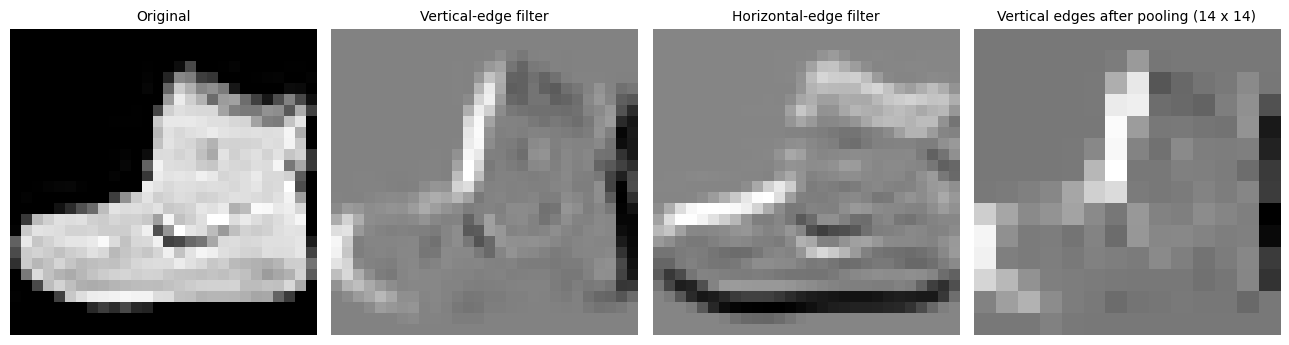

In [5]:
img = raw_train[0][0].unsqueeze(0)                         # a batch holding one image: (1, 1, 28, 28)

vertical_filter = torch.tensor([[-1., 0., 1.],
                                [-2., 0., 2.],
                                [-1., 0., 1.]]).view(1, 1, 3, 3)
horizontal_filter = vertical_filter.transpose(2, 3)

no_padding = F.conv2d(img, vertical_filter)                  # shrinks the image
with_padding = F.conv2d(img, vertical_filter, padding=1)     # keeps the size
pooled = F.max_pool2d(with_padding, 2)                       # halves the size

print("Original image      :", tuple(img.shape))
print("Convolution, no pad :", tuple(no_padding.shape))
print("Convolution, pad = 1:", tuple(with_padding.shape))
print("After max-pooling   :", tuple(pooled.shape))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
panels = [(img[0, 0], "Original"),
          (with_padding[0, 0], "Vertical-edge filter"),
          (F.conv2d(img, horizontal_filter, padding=1)[0, 0], "Horizontal-edge filter"),
          (pooled[0, 0], "Vertical edges after pooling (14 x 14)")]
for ax, (data, title) in zip(axes, panels):
    ax.imshow(data.numpy(), cmap="gray")
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.savefig("convolution_demo.png", dpi=150)
plt.show()

## Step 6: Build the two models

**Fully connected baseline (MLP):** flatten the image into 784 numbers, then two hidden layers.
It has no idea which pixels are next to each other.

**Small CNN:** two convolution blocks, then a small classifier.
1. `Conv2d(1 -> 16, 3 x 3, padding 1)` + ReLU + `MaxPool(2)`: finds 16 simple patterns such as edges, and shrinks 28 x 28 to 14 x 14
2. `Conv2d(16 -> 32, 3 x 3, padding 1)` + ReLU + `MaxPool(2)`: combines them into 32 larger patterns, and shrinks 14 x 14 to 7 x 7
3. Flatten (32 x 7 x 7 = 1568 numbers), then `Linear(1568 -> 64)` + ReLU + `Linear(64 -> 10)`: one score per category

The printout below follows one image through the CNN, so you can see the shape after every layer.

In [6]:
def make_mlp():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 256), nn.ReLU(),
        nn.Linear(256, 128), nn.ReLU(),
        nn.Linear(128, 10),
    )


def make_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(32 * 7 * 7, 64), nn.ReLU(),
        nn.Linear(64, 10),
    )


def count_params(model):
    return sum(p.numel() for p in model.parameters())


torch.manual_seed(42)
mlp = make_mlp()
torch.manual_seed(42)
cnn = make_cnn()
params_mlp, params_cnn = count_params(mlp), count_params(cnn)

print("Shape after each layer of the CNN (one image):")
x = torch.zeros(1, 1, 28, 28)
for layer in cnn:
    x = layer(x)
    print(f"  {layer.__class__.__name__:<10} -> {tuple(x.shape)}")

print(f"\nFully connected baseline: {params_mlp:,} trainable parameters")
print(f"Small CNN               : {params_cnn:,} trainable parameters")

Shape after each layer of the CNN (one image):
  Conv2d     -> (1, 16, 28, 28)
  ReLU       -> (1, 16, 28, 28)
  MaxPool2d  -> (1, 16, 14, 14)
  Conv2d     -> (1, 32, 14, 14)
  ReLU       -> (1, 32, 14, 14)
  MaxPool2d  -> (1, 32, 7, 7)
  Flatten    -> (1, 1568)
  Linear     -> (1, 64)
  ReLU       -> (1, 64)
  Linear     -> (1, 10)

Fully connected baseline: 235,146 trainable parameters
Small CNN               : 105,866 trainable parameters


## Step 7: Train both models

Both models use the same settings so the comparison is fair: Adam optimizer, learning rate 0.001, batch size 128, 10 epochs,
`CrossEntropyLoss` (softmax plus the loss for 10 classes). After every epoch we measure the validation accuracy and
keep the weights from the **best** epoch.

In [7]:
EPOCHS = 10
LEARNING_RATE = 0.001
loss_fn = nn.CrossEntropyLoss()


def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains if an optimizer is given, otherwise only measures."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            out = model(xb)                       # forward pass
            loss = loss_fn(out, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()                   # backpropagation
                optimizer.step()                  # update the weights
            total_loss += loss.item() * xb.size(0)
            correct += (out.argmax(dim=1) == yb).sum().item()
            count += xb.size(0)
    return total_loss / count, correct / count


def train_model(model, name, epochs=EPOCHS, lr=LEARNING_RATE):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc, best_state = 0.0, None
    start = time.time()
    print(f"--- Training: {name} ---")
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader)
        for key, value in zip(history, (tr_loss, va_loss, tr_acc, va_acc)):
            history[key].append(value)
        note = ""
        if va_acc > best_val_acc:
            best_val_acc, best_state = va_acc, copy.deepcopy(model.state_dict())
            note = "  <- best so far"
        print(f"Epoch {epoch:2d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f}{note}")
    seconds = time.time() - start
    model.load_state_dict(best_state)
    print(f"Restored the best weights (validation accuracy {best_val_acc:.4f}) | training time {seconds:.0f} s\n")
    return history, best_val_acc, seconds

In [8]:
mlp_hist, mlp_best, mlp_time = train_model(mlp, "Fully connected baseline")
cnn_hist, cnn_best, cnn_time = train_model(cnn, "Small CNN")

--- Training: Fully connected baseline ---


Epoch  1/10 | train loss 0.4938 acc 0.8209 | val loss 0.3982 acc 0.8523  <- best so far


Epoch  2/10 | train loss 0.3578 acc 0.8690 | val loss 0.3663 acc 0.8680  <- best so far


Epoch  3/10 | train loss 0.3135 acc 0.8841 | val loss 0.3365 acc 0.8788  <- best so far


Epoch  4/10 | train loss 0.2884 acc 0.8928 | val loss 0.3160 acc 0.8793  <- best so far


...

Epoch  6/10 | train loss 0.2369 acc 0.9141 | val loss 0.2832 acc 0.8963


Epoch  7/10 | train loss 0.2240 acc 0.9184 | val loss 0.2803 acc 0.8915


Epoch  8/10 | train loss 0.2103 acc 0.9232 | val loss 0.2475 acc 0.9113  <- best so far


Epoch  9/10 | train loss 0.1984 acc 0.9262 | val loss 0.2448 acc 0.9113


Epoch 10/10 | train loss 0.1908 acc 0.9299 | val loss 0.2555 acc 0.9078
Restored the best weights (validation accuracy 0.9113) | training time 346 s



## Step 8: Training and validation curves

Solid lines are the **validation** data (images the model is not trained on). Dashed lines are the **training** data.
- If the training line keeps improving while the validation line stalls or gets worse, the model is **overfitting** (memorising).
- A small gap between the two means the model generalises well.

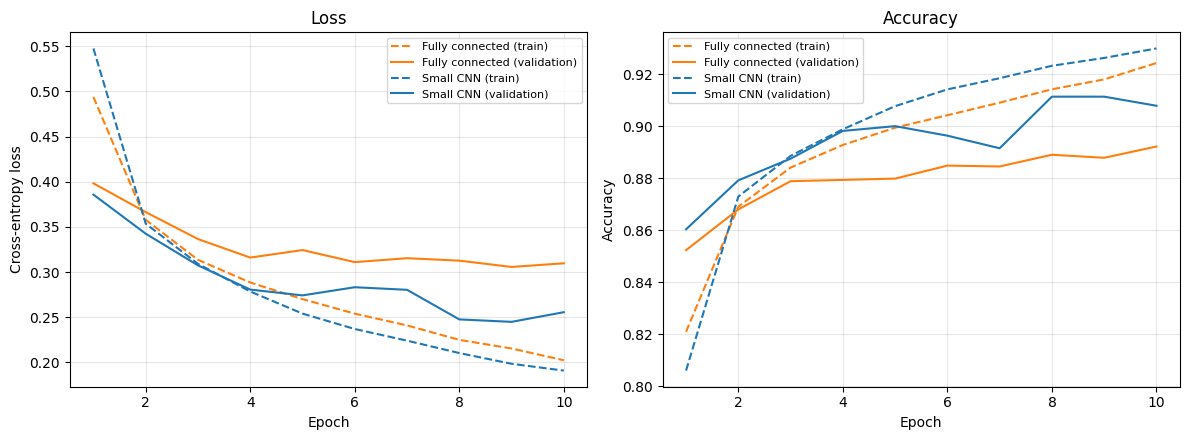

Fully connected : in the last epoch, training accuracy is +3.2 points above validation accuracy
Small CNN       : in the last epoch, training accuracy is +2.2 points above validation accuracy


In [9]:
epochs_axis = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for hist, label, color in [(mlp_hist, "Fully connected", "tab:orange"), (cnn_hist, "Small CNN", "tab:blue")]:
    axes[0].plot(epochs_axis, hist["train_loss"], "--", color=color, label=f"{label} (train)")
    axes[0].plot(epochs_axis, hist["val_loss"], "-", color=color, label=f"{label} (validation)")
    axes[1].plot(epochs_axis, hist["train_acc"], "--", color=color, label=f"{label} (train)")
    axes[1].plot(epochs_axis, hist["val_acc"], "-", color=color, label=f"{label} (validation)")
axes[0].set_title("Loss")
axes[0].set_ylabel("Cross-entropy loss")
axes[1].set_title("Accuracy")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

for name, hist in [("Fully connected", mlp_hist), ("Small CNN", cnn_hist)]:
    gap = (hist["train_acc"][-1] - hist["val_acc"][-1]) * 100
    print(f"{name:<16}: in the last epoch, training accuracy is {gap:+.1f} points above validation accuracy")

## Step 9: Compare the models on the test set

The test set has been untouched until now, so this is the honest comparison.

In [10]:
def predict_test(model):
    """Probabilities for all 10,000 test images (in the same order as test_raw)."""
    model.eval()
    all_probs, all_true = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            all_probs.append(torch.softmax(model(xb), dim=1).numpy())
            all_true.append(yb.numpy())
    return np.concatenate(all_probs), np.concatenate(all_true)


probs_mlp, y_true = predict_test(mlp)
probs_cnn, _ = predict_test(cnn)
pred_mlp, pred_cnn = probs_mlp.argmax(axis=1), probs_cnn.argmax(axis=1)
conf_cnn = probs_cnn.max(axis=1)
acc_mlp = float((pred_mlp == y_true).mean())
acc_cnn = float((pred_cnn == y_true).mean())

In [11]:
rows = [
    ("Fully connected", params_mlp, mlp_best, acc_mlp, mlp_time),
    ("Small CNN", params_cnn, cnn_best, acc_cnn, cnn_time),
]
print(f"{'Model':<18}{'Parameters':>12}{'Best val acc':>14}{'Test acc':>10}{'Wrong':>8}{'Train time':>12}")
print("-" * 74)
for name, params, val_acc, test_acc, secs in rows:
    wrong_n = int(round((1 - test_acc) * len(y_true)))
    print(f"{name:<18}{params:>12,}{val_acc * 100:>13.2f}%{test_acc * 100:>9.2f}%{wrong_n:>8}{secs:>10.0f} s")

diff = (acc_cnn - acc_mlp) * 100
print(f"\nThe CNN is {abs(diff):.2f} points {'better' if diff >= 0 else 'worse'} than the fully connected network "
      f"and uses {params_cnn / params_mlp * 100:.0f}% as many parameters.")

Model               Parameters  Best val acc  Test acc   Wrong  Train time
--------------------------------------------------------------------------
Fully connected        235,146        89.22%    88.65%    1135       189 s
Small CNN              105,866        91.13%    90.46%     954       346 s

The CNN is 1.81 points better than the fully connected network and uses 45% as many parameters.


### Accuracy for each clothing category

**Recall** for a category is the share of its test images the model got right. This shows *where* each model is strong or weak.

Category       Fully connected   Small CNN
------------------------------------------
T-shirt/top              84.3%       85.8%
Trouser                  97.9%       98.4%
Pullover                 76.0%       87.2%
Dress                    90.5%       86.7%
Coat                     86.4%       90.8%
Sandal                   96.6%       97.2%
Shirt                    67.2%       67.9%
Sneaker                  97.0%       98.2%
Bag                      97.3%       98.5%
Ankle boot               93.3%       93.9%


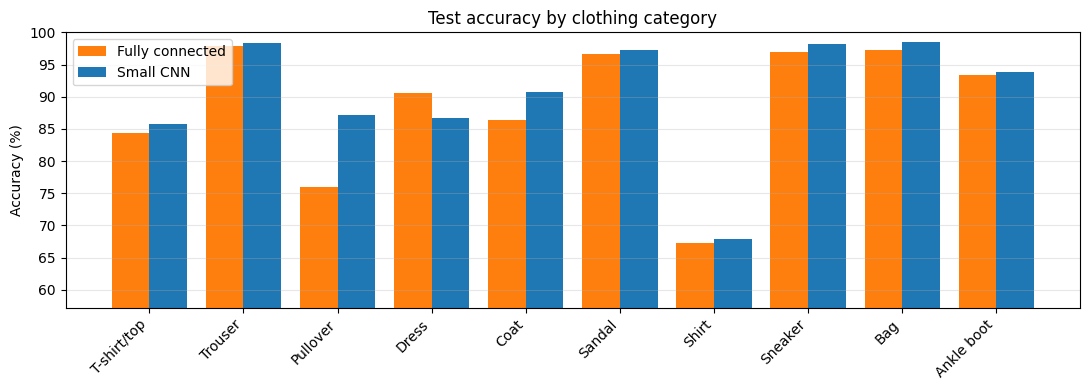

In [12]:
def confusion_matrix(y_true, y_pred, n_classes=10):
    """Rows = true category, columns = predicted category."""
    cm = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm


def top_confusions(cm, k=5):
    """The k most common mistakes as (count, true category, predicted category)."""
    off = cm.copy()
    np.fill_diagonal(off, 0)
    pairs = [(int(off[i, j]), i, j) for i in range(off.shape[0]) for j in range(off.shape[1]) if off[i, j] > 0]
    return sorted(pairs, reverse=True)[:k]


cm_mlp = confusion_matrix(y_true, pred_mlp)
cm_cnn = confusion_matrix(y_true, pred_cnn)
recall_mlp = np.diag(cm_mlp) / cm_mlp.sum(axis=1)
recall_cnn = np.diag(cm_cnn) / cm_cnn.sum(axis=1)

print(f"{'Category':<14}{'Fully connected':>16}{'Small CNN':>12}")
print("-" * 42)
for c, name in enumerate(CLASS_NAMES):
    print(f"{name:<14}{recall_mlp[c] * 100:>15.1f}%{recall_cnn[c] * 100:>11.1f}%")

x = np.arange(10)
plt.figure(figsize=(11, 4))
plt.bar(x - 0.2, recall_mlp * 100, width=0.4, label="Fully connected", color="tab:orange")
plt.bar(x + 0.2, recall_cnn * 100, width=0.4, label="Small CNN", color="tab:blue")
plt.xticks(x, CLASS_NAMES, rotation=45, ha="right")
plt.ylabel("Accuracy (%)")
plt.ylim(max(0, min(recall_mlp.min(), recall_cnn.min()) * 100 - 10), 100)
plt.title("Test accuracy by clothing category")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("per_class_accuracy.png", dpi=150)
plt.show()

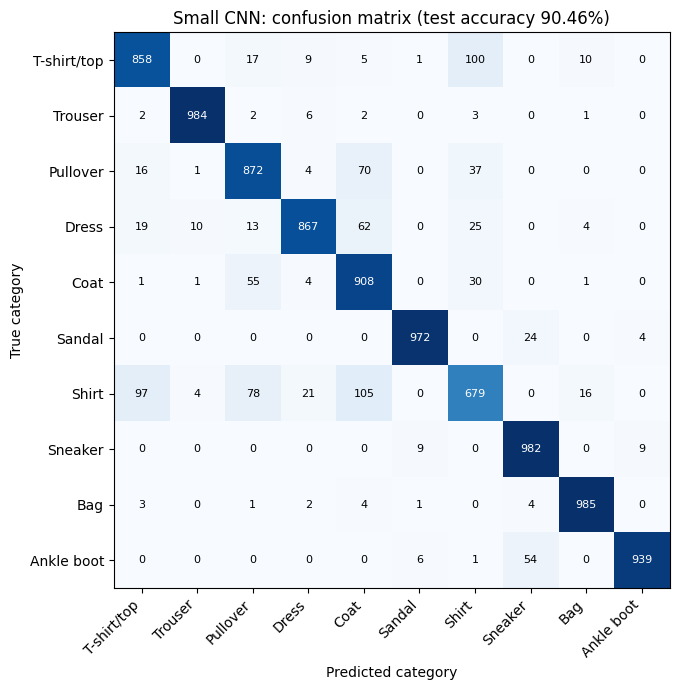

Most common mistakes of the CNN (true -> predicted):
  Shirt -> Coat: 105 times
  T-shirt/top -> Shirt: 100 times
  Shirt -> T-shirt/top: 97 times
  Shirt -> Pullover: 78 times
  Pullover -> Coat: 70 times


In [13]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(cm_cnn, cmap="Blues")
ax.set_title(f"Small CNN: confusion matrix (test accuracy {acc_cnn * 100:.2f}%)")
ax.set_xlabel("Predicted category")
ax.set_ylabel("True category")
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_yticklabels(CLASS_NAMES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, str(cm_cnn[i, j]), ha="center", va="center", fontsize=8,
                color="white" if cm_cnn[i, j] > cm_cnn.max() / 2 else "black")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

print("Most common mistakes of the CNN (true -> predicted):")
for count, i, j in top_confusions(cm_cnn, 5):
    print(f"  {CLASS_NAMES[i]} -> {CLASS_NAMES[j]}: {count} times")

## Step 10: Explain five misclassified examples

We take the **five mistakes the CNN was most confident about**, because a confident mistake is the most interesting to study.
For each one the table shows the true category, the prediction, the confidence, and how much probability the model gave to the **true** category.

The notebook also prints a **draft note** for each example. Treat it as a starting point: look at the picture,
decide whether it really applies, and rewrite it in your own words in the Markdown cell below.

The CNN got 954 of 10000 test images wrong.



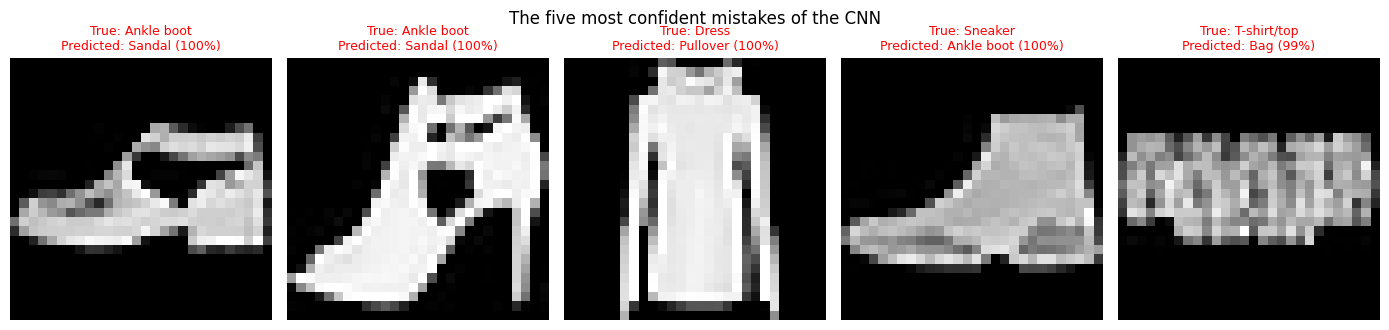

#  True          Predicted      Confidence  P(true class)
---------------------------------------------------------
1  Ankle boot    Sandal              99.8%           0.1%
2  Ankle boot    Sandal              99.8%           0.2%
3  Dress         Pullover            99.7%           0.0%
4  Sneaker       Ankle boot          99.7%           0.3%
5  T-shirt/top   Bag                 99.4%           0.2%

Draft notes (rewrite them in your own words after looking at each picture):
1. Both are footwear. At 28 x 28 pixels, the details that separate an Ankle boot from a Sandal (straps, sole and height of the shaft) almost disappear.
2. Both are footwear. At 28 x 28 pixels, the details that separate an Ankle boot from a Sandal (straps, sole and height of the shaft) almost disappear.
3. This Dress has an unusual shape or pattern, and at this low resolution it resembles a Pullover.
4. Both are footwear. At 28 x 28 pixels, the details that separate a Sneaker from an Ankle boot (straps, sole and 

In [14]:
wrong = np.where(pred_cnn != y_true)[0]
print(f"The CNN got {len(wrong)} of {len(y_true)} test images wrong.\n")

five = wrong[np.argsort(-conf_cnn[wrong])][:5]        # the five most confident mistakes

fig, axes = plt.subplots(1, 5, figsize=(14, 3.4))
for ax, i in zip(axes, five):
    ax.imshow(test_raw[i], cmap="gray")
    ax.set_title(f"True: {CLASS_NAMES[y_true[i]]}\nPredicted: {CLASS_NAMES[pred_cnn[i]]} ({conf_cnn[i] * 100:.0f}%)",
                 color="red", fontsize=9)
    ax.axis("off")
plt.suptitle("The five most confident mistakes of the CNN")
plt.tight_layout()
plt.savefig("misclassified.png", dpi=150)
plt.show()

SIMILAR_GROUPS = {
    "upper-body clothes (tops, sweaters and coats)": ({"T-shirt/top", "Pullover", "Coat", "Shirt"},
                                                     "collar, sleeves, length and buttons"),
    "footwear": ({"Sandal", "Sneaker", "Ankle boot"}, "straps, sole and height of the shaft"),
}


def with_article(name):
    return ("an " if name[0].lower() in "aeiou" else "a ") + name


def draft_reason(true_name, pred_name):
    for group, (members, details) in SIMILAR_GROUPS.items():
        if true_name in members and pred_name in members:
            return (f"Both are {group}. At 28 x 28 pixels, the details that separate {with_article(true_name)} "
                    f"from {with_article(pred_name)} ({details}) almost disappear.")
    return (f"This {true_name} has an unusual shape or pattern, and at this low resolution "
            f"it resembles {with_article(pred_name)}.")


print(f"{'#':<3}{'True':<14}{'Predicted':<14}{'Confidence':>11}{'P(true class)':>15}")
print("-" * 57)
for n, i in enumerate(five, start=1):
    print(f"{n:<3}{CLASS_NAMES[y_true[i]]:<14}{CLASS_NAMES[pred_cnn[i]]:<14}"
          f"{conf_cnn[i] * 100:>10.1f}%{probs_cnn[i, y_true[i]] * 100:>14.1f}%")

print("\nDraft notes (rewrite them in your own words after looking at each picture):")
for n, i in enumerate(five, start=1):
    print(f"{n}. {draft_reason(CLASS_NAMES[y_true[i]], CLASS_NAMES[pred_cnn[i]])}")

**Write your explanation of the five misclassified examples here** (one or two sentences each, in your own words,
looking at the picture above): what does the item look like, why could the model confuse it, and what could help the model?

1. Example 1 (true ___, predicted ___):
2. Example 2 (true ___, predicted ___):
3. Example 3 (true ___, predicted ___):
4. Example 4 (true ___, predicted ___):
5. Example 5 (true ___, predicted ___):

## Step 11: Summary and conclusion

The cell below collects the key numbers (and saves them as `results.json` and `results_summary.md`, ready to paste into your README).

In [15]:
gap_mlp = (mlp_hist["train_acc"][-1] - mlp_hist["val_acc"][-1]) * 100
gap_cnn = (cnn_hist["train_acc"][-1] - cnn_hist["val_acc"][-1]) * 100
better = "CNN" if acc_cnn > acc_mlp else "fully connected network"
hardest = CLASS_NAMES[int(np.argmin(recall_cnn))]
easiest = CLASS_NAMES[int(np.argmax(recall_cnn))]

summary = f"""## Results

| Model | Parameters | Best validation accuracy | Test accuracy |
|---|---|---|---|
| Fully connected baseline | {params_mlp:,} | {mlp_best * 100:.2f}% | {acc_mlp * 100:.2f}% |
| Small CNN | {params_cnn:,} | {cnn_best * 100:.2f}% | {acc_cnn * 100:.2f}% |

- The {better} was better: the CNN is {diff:+.2f} points on the test set while using {params_cnn / params_mlp * 100:.0f}% as many parameters.
- Easiest category for the CNN: {easiest} ({recall_cnn.max() * 100:.1f}%). Hardest: {hardest} ({recall_cnn.min() * 100:.1f}%).
- Most common CNN mistake: {CLASS_NAMES[top_confusions(cm_cnn, 1)[0][1]]} predicted as {CLASS_NAMES[top_confusions(cm_cnn, 1)[0][2]]}.
- Train minus validation accuracy in the last epoch: {gap_mlp:+.1f} points (fully connected) and {gap_cnn:+.1f} points (CNN).
"""
print(summary)

Path("results_summary.md").write_text(summary, encoding="utf-8")
results = {
    "fully_connected": {"parameters": params_mlp, "best_val_acc": round(mlp_best, 4), "test_acc": round(acc_mlp, 4)},
    "small_cnn": {"parameters": params_cnn, "best_val_acc": round(cnn_best, 4), "test_acc": round(acc_cnn, 4)},
    "hardest_category": hardest,
    "easiest_category": easiest,
}
Path("results.json").write_text(json.dumps(results, indent=2), encoding="utf-8")

## Results

| Model | Parameters | Best validation accuracy | Test accuracy |
|---|---|---|---|
| Fully connected baseline | 235,146 | 89.22% | 88.65% |
| Small CNN | 105,866 | 91.13% | 90.46% |

- The CNN was better: the CNN is +1.81 points on the test set while using 45% as many parameters.
- Easiest category for the CNN: Bag (98.5%). Hardest: Shirt (67.9%).
- Most common CNN mistake: Shirt predicted as Coat.
- Train minus validation accuracy in the last epoch: +3.2 points (fully connected) and +2.2 points (CNN).



266

**Your conclusion** (3 to 5 sentences, using the numbers printed above):

- Which model performed better on the test set, and by how much?
- Why does a CNN suit images better than a fully connected network? (Think about neighbouring pixels, shared filters and parameter count.)
- Which categories were the hardest, and why?
- What would you try next to improve the result?

Your conclusion: